# ИМПОРТ БИБЛИОТЕК

In [2]:
import requests
import pandas as pd
import numpy as np
import typing

from datetime import datetime
from datetime import timedelta

import matplotlib.pyplot as plt

# МОДУЛЬ УСТАНОВЛЕНИЯ ПАРАМЕТРОВ СТРУКТУРНОГО ПРОДУКТА

In [3]:
def sp_params():

  #номинал
  while True:
    try:
      principal = float(input("Введите номинал (в валюте или %) "))
      break
    except ValueError:
      print("Должно быть число")

  #дата Первоначального значения
  while True:
    try:
      init_date = datetime.strptime(input("Введите дату Первоначального значения (цены акций) ")
                  , "%Y-%m-%d").date()
      break
    except ValueError:
      print("Неверный формат даты. Используйте YYYY-MM-DD. ")

  #Фиксированнаый купонный доход
  print("#### Купонный доход по облигациям ####")
  while True:
    try:
      coupon = float(input("Введите ставку фиксированного дохода"))
      break
    except ValueError:
      print("Должно быть число")

  print("#### Дополнительный доход по облигациям #####")

  # #Количество наблюдений

  while True:
    try:
      n_obs = int(input("Введите количество дат-наблюдения (включая  дату погашения)"))
      break
    except ValueError:
      print("Должно быть число")

  #Ввод дат наблюдения
  obs_dates = []
  for i in range(n_obs):
    while True:
      try:
        obs_date = datetime.strptime(input(f"Введите Даты выплаты Дополнительного дохода: порядковый номер {i+1} ")
                    , "%Y-%m-%d").date()
        obs_dates.append(obs_date)
        break
      except ValueError:
        print("Неверный формат даты. Используйте YYYY-MM-DD")

  #Ввод барьеров дополнительного дохода
  barriers_add_coupon = []
  for i in range(n_obs):
    while True:
      try:
        date_temp = datetime.strftime(obs_dates[i],"%Y-%m-%d")
        barrier_add_coupon = float(
            input(
            f"Введите размер барьера для выплаты дополнительного купона на {date_temp}, % ")
        )
        barriers_add_coupon.append(barrier_add_coupon)
        break
      except ValueError:
        print("Должно быть число")


  #Дополнительный доход (купон)
  while True:
    try:
      add_coupon = float(input("Введите размер дополнительного купона, % "))
      break
    except ValueError:
      print("Должно быть число")

  print("#### Условия погашения облигаций #####")
  print("#### Барьеры отзыва #####")

  #Значения барьеров отзыва (их количество
  #предполагается на 1 меньше, чем дат наблюдения)
  #Даты наблюдения также должны совпадать
  #Последняя дата - барьер погашения, а не отзыва

  call_bars = []
  for i in range(n_obs-1):
      while True:
        try:
          date_temp = datetime.strftime(obs_dates[i],"%Y-%m-%d")
          call_bar = float(input(f"Введите размер барьера отзыва для {date_temp}, % "))
          call_bars.append(call_bar)
          break
        except ValueError:
          print("Должно быть число")

  print("#### Барьер погашения #####")

  while True:
    try:
      date_temp = datetime.strftime(obs_dates[-1],"%Y-%m-%d")
      redemption_bar = float(input(f"Введите размер барьера погашения для {date_temp} даты, % "))
      break
    except ValueError:
      print("Должно быть число")

  print("","### Проверьте параметры ###", sep = "\n")
  print("Номинал облигации: ", principal)
  print("Дата оценки для определения первоначальной цены акций в корзине: ", init_date)
  print("Фиксированный купонный доход: ",coupon )
  print("Количество наблюдений: ", n_obs)
  print("Даты наблюдений: ", [datetime.strftime(obs_dates[i],"%Y-%m-%d") for i in range(len(obs_dates))])
  print("Барьеры для выплаты дополнительного купона (выплаты, если не ниже, чем барьер): ", barriers_add_coupon)
  print(f"Размер дополнительного купона {add_coupon}%")
  print("Барьеры для досрочного отзыва по 100% (отзыв, если выше, чем барьер): ", call_bars)
  print("Барьер для погашения по 100% от номинала (если ниже, то действует иное условие): ", redemption_bar)

  return {"principal": principal,
          "init_date": init_date,
          "coupon":coupon,
          "n_obs":n_obs,
          "obs_dates":obs_dates,
          "barriers_add_coupon":barriers_add_coupon,
          "add_coupon":add_coupon,
          "call_bars":call_bars,
          "redemption_bar":redemption_bar
          }

# МОДУЛЬ ЗАГРУЗКИ ИСТОРИЧЕСКИХ ДАННЫХ И РАСЧЕТА ВОЛАТИЛЬНОСТИ / ДОХОДНОСТИ

In [4]:
def get_historical_data(ticker, start_date, end_date):
  '''
  Выгружает исторические данные для всех ticker
  за все торговые дни за период, начиная со start_date, заканчивая end_date
  '''

  url = f"https://iss.moex.com/iss/history/engines/stock/markets/shares/boards/TQBR/securities/{ticker}.json"
  params = {
      'from': start_date,
      'till': end_date,
      'interval': '24',  # дневные данные
      'start': 0
  }

  all_data = []
  start = 0
  while True:
      params['start'] = start
      response = requests.get(url, params=params)
      data = response.json()
      history = data['history']['data']
      if not history:
          break
      all_data.extend(history)
      start += 100

  if not all_data:
      return pd.DataFrame()

  columns = data['history']['columns']
  df = pd.DataFrame(all_data, columns=columns)

  # Оставляем только нужные колонки и преобразуем дату
  df = df[['TRADEDATE', 'CLOSE']]
  df['TRADEDATE'] = pd.to_datetime(df['TRADEDATE'])
  df.set_index('TRADEDATE', inplace=True)
  df.sort_index(inplace=True)
  df['CLOSE'] = pd.to_numeric(df['CLOSE'], errors='coerce')
  df = df.dropna()

  return df

In [5]:
def get_basket_hist_data():
  '''
  Возвращает dict с DataFrame, содержащими исторические данные за выбранный период
  '''
  print("","### Выгрузка исторических данных ###",
        "Конечная дата загрузки должна быть не раньше, чем дата оценки", "", sep = "\n")
  while True:
    try:
      end_period = input("Укажите конечную дату исторического периода (YYYY-MM-DD): ")
      end_period_val = datetime.strptime(end_period, "%Y-%m-%d").date()
      break
    except ValueError:
      print("Неверный формат даты. Используйте YYYY-MM-DD.")

  #Период, за который выгрузятся данные
  while True:
    try:
      years = int(input("Укажите период (количество лет), за который необходимо выгрузить исторические данные "))
      start_date = (end_period_val - timedelta(days=years*365)).strftime('%Y-%m-%d')
      print(f"Период выгрузки данных {start_date} - {end_period}","",sep = "\n")
      break
    except ValueError:
      print("Ошибка. Используйте целое число")

  #Выбор акций, которые идут в продукт
  # PLZL - Полюс, ALRS - Алроса, UGLD - ЮГК, SELG - Селегдар,
  basket = []
  ticker = ""

  while(ticker != "-1"):
    ticker = input("Укажите тикер акции. Чтобы остановить ввод, введите -1 ")
    if(ticker != "-1"):
      basket.append(ticker)

  print("",f"Корзина акций {basket}", sep = "\n")

  basket_data = {}
  for ticker in basket:
      print(f"Загружаем данные для {ticker} за {years} лет за период с {start_date} по {end_period}...")
      data = get_historical_data(ticker, start_date, end_period)
      if not data.empty:
          basket_data[ticker] = data
      else:
          print(f"Нет данных для {ticker}")
  print("","Загрузка завершена",sep = "\n")
  return basket_data

In [6]:
def get_basket_vols(basket_data):
  '''
  Возвращает значения исторической волатильности для каждой акции в корзине
  '''
  def calculate_volatility(basket_data_close):
    returns = np.log(basket_data_close / basket_data_close.shift(1)).dropna()
    # Годовая волатильность (предполагаем 252 торговых дня в году - ASSUMPTION)
    daily_volatility = returns.std()
    annualized_volatility = daily_volatility * np.sqrt(252)
    return annualized_volatility

  print("","### Расчет исторической волатильности ###",sep = "\n")
  print("* Период для расчета не должен выходить за даты, для которых выгружались исторические данные")

  while True:
    try:
      end_period = input("Укажите конечную дату для расчета волатильности (YYYY-MM-DD): ")
      end_period_val = datetime.strptime(end_period, "%Y-%m-%d").date()
      break
    except ValueError:
      print("Неверный формат даты. Используйте YYYY-MM-DD.")

  while True:
    try:
      start_period = input("Укажите начальную дату для расчета волатильности (YYYY-MM-DD): ")
      start_period_val = datetime.strptime(end_period, "%Y-%m-%d").date()
      break
    except ValueError:
      print("Неверный формат даты. Используйте YYYY-MM-DD.")

  print(f"Средняя годовая волатильность за период c {start_period} по {end_period}")
  vols = {}
  for ticker, data in basket_data.items():
    vol = calculate_volatility(data['CLOSE'].loc[start_period:end_period])
    vols[ticker] = vol
    print(f"{ticker}:{vol:.2%}")

  return vols

def get_basket_returns(basket_data):
  '''
  Возвращает значения исторической доходности для каждой акции в корзине
  Возвращает все доходности на все дни (используется далее как маска для нахождения прыжков)
  '''
  def calculate_returns(basket_data_close):
    returns = np.log(basket_data_close / basket_data_close.shift(1)).dropna()
    # Годовая волатильность (предполагаем 252 торговых дня в году - ASSUMPTION)
    mean_return = np.mean(returns)
    return mean_return

  print("","### Расчет исторической доходности ###",sep = "\n")
  print("* Период для расчета не должен выходить за даты, для которых выгружались исторические данные")

  while True:
    try:
      end_period = input("Укажите конечную дату для расчета доходности (YYYY-MM-DD): ")
      end_period_val = datetime.strptime(end_period, "%Y-%m-%d").date()
      break
    except ValueError:
      print("Неверный формат даты. Используйте YYYY-MM-DD.")

  while True:
    try:
      start_period = input("Укажите начальную дату для расчета доходности (YYYY-MM-DD): ")
      start_period_val = datetime.strptime(end_period, "%Y-%m-%d").date()
      break
    except ValueError:
      print("Неверный формат даты. Используйте YYYY-MM-DD.")

  print(f"Средняя дневная доходность за период c {start_period} по {end_period}")
  rets = {}
  for ticker, data in basket_data.items():
    ret = calculate_returns(data['CLOSE'].loc[start_period:end_period])
    rets[ticker] = ret
    print(f"{ticker}:{ret:.2%}")

  all_returns = {}
  for ticker, data in basket_data.items():
    data_temp = data['CLOSE'].loc[start_period:end_period]
    returns = np.log(data_temp / data_temp.shift(1)).dropna()
    all_returns.update({ticker:returns})
  return rets, all_returns

### Параметры для процесса с прыжками (Merton jumps)

Процесс Мертона - это GBM + Случайные прыжки, которые подчиняются случайному процессу Пуассона:


In [7]:
if(np.nan):
  print(1)
else:
  print(0)

1


In [8]:
def detect_jumps(returns, threshold=3.0):
    """
    returns <- np.array
    Возвращает dict с тикерами и датами прыжков и их размером (дневная доходность)
    """
    all_jumps = dict()
    for item, value in returns.items():
        mean_return = value.mean()
        std_return = value.std()
        jump_mask = np.abs(value - mean_return) > threshold * std_return
        jump_dates = value[jump_mask].dropna().index
        jump_sizes = value[jump_mask].dropna().values
        all_jumps.update({item:(jump_dates,jump_sizes)})
    return all_jumps

def jump_params(returns, dict_stock_jumps,trading_days = 252):
    all_jumps_params = dict()
    for item, value in dict_stock_jumps.items():
        n_years = len(returns[item])/trading_days
        n_jumps = 0 if np.isnan(len(dict_stock_jumps[item][1])) else len(dict_stock_jumps[item][1])
        lambda_ = n_jumps/n_years

        jump_mean = 0 if np.isnan(np.mean(dict_stock_jumps[item][1])) else np.mean(dict_stock_jumps[item][1])
        jump_sigma = 0 if np.isnan(np.std(dict_stock_jumps[item][1])) else np.std(dict_stock_jumps[item][1])
        jump_param_temp = {"n_jumps":n_jumps,"lambda":lambda_,"jump_mean":jump_mean,"jump_sigma":jump_sigma}
        all_jumps_params.update({item:jump_param_temp})
    return all_jumps_params

# МОДУЛЬ СИМУЛЯЦИЙ ДВИЖЕНИЯ КОРЗИНЫ АКЦИЙ (МОНТЕ-КАРЛО)

In [9]:
def set_val_date():
  while True:
    try:
      val_date = input("Укажите дату оценки ")
      val_date_strp = datetime.strptime(val_date,"%Y-%m-%d").date()
      break
    except ValueError:
      print("Неверный формат даты. Используйте YYYY-MM-DD.")
  return val_date_strp

def set_divs():
  divs = {}
  divs["ALRS"] = 5.37
  divs["PLZL"] = 3.18
  divs["SELG"] = 5.12
  divs["UGLD"] = 0.01
  return divs

def gen_paths(val_date_strp:datetime,
              basket_data:dict,
              vols:dict,
              j_params:dict,
              N:int = 100):

  '''
  historical_date - dict из загрузки функцией get_historical_data()
  vols - dict с волатильностями по всем тикерами
  N - количество итераций
  даты оценки необходимо указывать как дату торгового дня, на которые есть данные
  '''
  val_date = datetime.strftime(val_date_strp,"%Y-%m-%d")

  #int количество дней, на которые будет проводиться симуляция
  mat_date_strp = datetime.strptime(input("Укажите дату погашения продукта (период для симуляции)"),"%Y-%m-%d").date()
  sim_period = (mat_date_strp - val_date_strp).days

  #rf ставка на период симуляции
  r = float(input(f"Укажите безрисковую ставку (непрерывное начисление) на {sim_period} дней/дня <=> {(sim_period/365):.2f} лет "))/100

  #дивиденды на период симуляции для каждой акции
  # divs = {}
  # for ticker in basket_data:
  #   divs[ticker] = float(input(f"Укажите дивиденды (в непрерыном начислении) для {ticker}:" ))
  divs = set_divs()

  #steps
  T = sim_period/365
  steps = sim_period

  dt = T / steps
  time_grid = np.linspace(0, T, steps + 1)

  #dict, который будет хранить все paths
  paths_dict = {}

  for ticker in basket_data:
    S0 = basket_data[ticker].loc[val_date,:].item()
    sigma = vols[ticker].item()
    q = divs[ticker]
    #параметры прыжков
    lambda_j = j_params[ticker]["lambda"]
    mu_j = j_params[ticker]["jump_mean"]
    sigma_j = j_params[ticker]["jump_sigma"]

    #генерация пустых путей и вставка в нулевой период значение S0
    paths = np.zeros((N, steps + 1))
    paths[:, 0] = S0

    #генерация значений
    for i in range(N):
      S = S0
      for t in range(1, steps + 1):
          Z = np.random.normal()
          J = np.random.poisson(lambda_j * dt)
          jump_multiplier = np.exp(np.random.normal(mu_j, sigma_j, J)).prod() if J > 0 else 1.0
          dS = ((r - q)/100- lambda_j * (np.exp(mu_j + 0.5 * sigma_j ** 2) - 1)) * dt + sigma * np.sqrt(dt) * Z
          S = S * np.exp(dS) * jump_multiplier
          paths[i, t] = S

    paths_dict[ticker] = paths
  print("Симуляции проведены")
  return paths_dict


# МОДУЛЬ ОЦЕНКИ СПРАВЕДЛИВОЙ СТОИМОСТИ СТРУКТУРНОГО ПРОДУКТА

## Phoenix with memory

In [10]:
def calculate_product_value(product, basket_data, paths, evaluation_date, discount_factors):
    """
    Расчет справедливой стоимости структурного продукта

    Параметры:
    - product: dict с параметрами продукта из sp_params()
    - basket_data: исторические данные {тикер: DataFrame}
    - paths: смоделированные цены {тикер: array(simulations x days)}
    - evaluation_date: дата оценки (datetime)
    - discount_factors: {дата выплаты: дисконт-фактор}

    Возвращает:
    - (fair_value, payoffs, stats)
    """
    # Преобразуем даты наблюдения в datetime.date для сравнения
    obs_dates = product['obs_dates']
    payment_dates = product['obs_dates']  # Даты выплат совпадают с наблюдениями - упрошение

    # Количество симуляций
    n_simulations = next(iter(paths.values())).shape[0]
    tickers = list(paths.keys())

    # Изначальные значения
    init_prices = {t: basket_data[t].loc[str(product['init_date']), 'CLOSE'] for t in tickers}

    # Инициализация результатов
    payoffs = np.zeros(n_simulations)
    discounted_payoffs = np.zeros(n_simulations)

    # Эффект памяти
    memory_global = 0
    for j, obs_date in enumerate(obs_dates):
      if obs_date <= evaluation_date:
        prices = {t: basket_data[t].loc[str(obs_date), 'CLOSE'] for t in tickers}
        perf = {k:prices[k] / init_prices[k] for k in prices if k in init_prices}
        worst_perf = min(perf.values())
        if worst_perf < product['barriers_add_coupon'][j]:
          memory_global += 1

    # Для каждой симуляции
    for i in range(n_simulations):

        autocall_triggered = False
        total_additional_income = 0
        memory = memory_global

        # Проверяем условия для каждой даты наблюдения <-- Если она погасилась, мы и так это увидим. Если выплатила купон, то это не влияет на цену. Если запомнила, то это учтено.
        for j, obs_date in enumerate(obs_dates):
            if obs_date < evaluation_date:
                # C прошедшими датами наблюдений ничего не делаем
                pass
            else:
                # Используем смоделированные данные
                # Предполагается, что paths начинается с evaluation_date
                day_idx = (obs_date - evaluation_date).days
                prices = {t: paths[t][i, day_idx] for t in tickers}

                # Проверка автоколла (первые n-1 дат)
                if j < len(product['call_bars']) and not autocall_triggered:
                    # Для проверки достаточно посмотреть на worst_perf
                    perf = {k:prices[k] / init_prices[k] for k in prices if k in init_prices}
                    worst_perf = min(perf.values())
                    if worst_perf >= product['call_bars'][j]/100:
                      # Автоколл сработал
                      payment = product['principal'] + product['principal'] * (product['add_coupon']/100 + product['add_coupon']/100*memory) # Добавляем купон и учитываем эффект памяти (при наличии)# Выплата номинала
                      payoffs[i] += payment
                      memory = 0
                      # Дисконтируем выплату
                      discounted_payoffs[i] += payment * discount_factors.get(evaluation_date).get(
                          payment_dates[j],1.0)

                      autocall_triggered = True
                      break
                    elif worst_perf >= product['barriers_add_coupon'][j]/100:
                      payment = product['principal'] * (product['add_coupon']/100 + product['add_coupon']/100*memory) # Выплачиваем купон с учетом памяти и продолжаем жить
                      payoffs[i] += payment
                      memory = 0
                      discounted_payoffs[i] += payment * discount_factors.get(evaluation_date).get(
                          payment_dates[j],1.0)
                    else:
                      memory += 1

                # Погашение
                else:
                    perf = {k:prices[k] / init_prices[k] for k in prices if k in init_prices}
                    worst_perf = min(perf.values())
                    if worst_perf >= product['redemption_bar']/100:
                      #Погашение по номиналу + выплата купона
                      payment = product['principal'] + product['principal'] * (product['add_coupon']/100 + product['add_coupon']/100*memory)
                      payoffs[i] += payment
                      # Дисконтируем выплату
                      discounted_payoffs[i] += payment * discount_factors.get(evaluation_date).get(
                          payment_dates[j],1.0)
                    else:
                      payment = product['principal']*worst_perf
                      payoffs[i] = payment
                      discounted_payoffs[i] = payment * discount_factors.get(evaluation_date).get(
                          payment_dates[j],1.0)

    # Расчет статистик
    fair_value = np.mean(discounted_payoffs)
    stats = {
        'fair_value': fair_value,
        # 'autocall_prob': np.mean([p > product['principal'] for p in payoffs]),
        'avg_payoff': np.mean(payoffs),
        'min_payoff': np.min(payoffs),
        'max_payoff': np.max(payoffs),
        'payoff_std': np.std(payoffs)
    }

    return fair_value, payoffs, discounted_payoffs, stats

# VALUATION

In [ ]:
#Параметры сруктурного продукта
print("","- МОДУЛЬ УСТАНОВЛЕНИЯ ПАРАМЕТРОВ СТРУКТУРНОГО ПРОДУКТА -",sep = "\n")
product = sp_params()

print("","- МОДУЛЬ ЗАГРУЗКИ ИСТОРИЧЕСКИХ ДАННЫХ И РАСЧЕТА ВОЛАТИЛЬНОСТИ / ДОХОДНОСТИ -",sep = "\n")
#Исторические данные по корзине акций
basket_data = get_basket_hist_data()


# vols = {'PLZL': np.float64(0.3335),
#  'ALRS': np.float64(0.3444),
#  'SELG': np.float64(0.4684),
#  'UGLD': np.float64(0.4287)}

vols = get_basket_vols(basket_data)
rets, all_returns = get_basket_returns(basket_data)

print("","- МОДУЛЬ СИМУЛЯЦИЙ ДВИЖЕНИЯ КОРЗИНЫ АКЦИЙ (МОНТЕ-КАРЛО)-",sep = "\n")

#Генерация блужданий (paths) для каждой акции

# Процесс Мертона
# Характеристика прыжков
j_params = jump_params(all_returns,detect_jumps(all_returns,threshold = 3))

# # Установка даты оценки и генераций блужданий
# # Здесь также устанавливаетя количество симуляций

val_date = set_val_date()
paths = gen_paths(val_date,basket_data,vols,j_params,1000
                  )

print("","- МОДУЛЬ ОЦЕНКИ СПРАВЕДЛИВОЙ СТОИМОСТИ СТРУКТУРНОГО ПРОДУКТА -", sep = "\n")

#19.06.2024 (дата размещения), 30.12.2024, 30.03.2025

# Дисконт-факторы
discount_factors = {
    datetime(2024, 6, 19).date():{
    datetime(2024, 9, 19).date(): 0.9561,
    datetime(2024, 12, 19).date(): 0.9139,
    datetime(2025, 3, 19).date(): 0.8749,
    datetime(2025, 6, 19).date(): 0.8375},

    datetime(2024, 12, 30,9).date():{
    datetime(2024, 9, 19).date(): 1.0,
    datetime(2024, 12, 19).date(): 1.0,
    datetime(2025, 3, 19).date(): 0.9512,
    datetime(2025, 6, 19).date(): 0.9028},

    datetime(2025, 3, 28).date():{
    datetime(2024, 9, 19).date(): 1.0,
    datetime(2024, 12, 19).date(): 1.0,
    datetime(2025, 3, 19).date(): 1.0,
    datetime(2025, 6, 19).date(): 0.9496}

}

fair_value, payoffs, discounted_payoffs, stats = calculate_product_value(
    product, basket_data, paths, val_date, discount_factors
)


- МОДУЛЬ УСТАНОВЛЕНИЯ ПАРАМЕТРОВ СТРУКТУРНОГО ПРОДУКТА -
Неверный формат даты. Используйте YYYY-MM-DD. 
Неверный формат даты. Используйте YYYY-MM-DD. 
Неверный формат даты. Используйте YYYY-MM-DD. 
Неверный формат даты. Используйте YYYY-MM-DD. 
Неверный формат даты. Используйте YYYY-MM-DD. 
Неверный формат даты. Используйте YYYY-MM-DD. 
Неверный формат даты. Используйте YYYY-MM-DD. 
Неверный формат даты. Используйте YYYY-MM-DD. 
Неверный формат даты. Используйте YYYY-MM-DD. 
Неверный формат даты. Используйте YYYY-MM-DD. 
Неверный формат даты. Используйте YYYY-MM-DD. 
Неверный формат даты. Используйте YYYY-MM-DD. 
Неверный формат даты. Используйте YYYY-MM-DD. 
Неверный формат даты. Используйте YYYY-MM-DD. 
Неверный формат даты. Используйте YYYY-MM-DD. 
Неверный формат даты. Используйте YYYY-MM-DD. 
Неверный формат даты. Используйте YYYY-MM-DD. 
Неверный формат даты. Используйте YYYY-MM-DD. 
Неверный формат даты. Используйте YYYY-MM-DD. 
Неверный формат даты. Используйте YYYY-MM-DD. 
Не

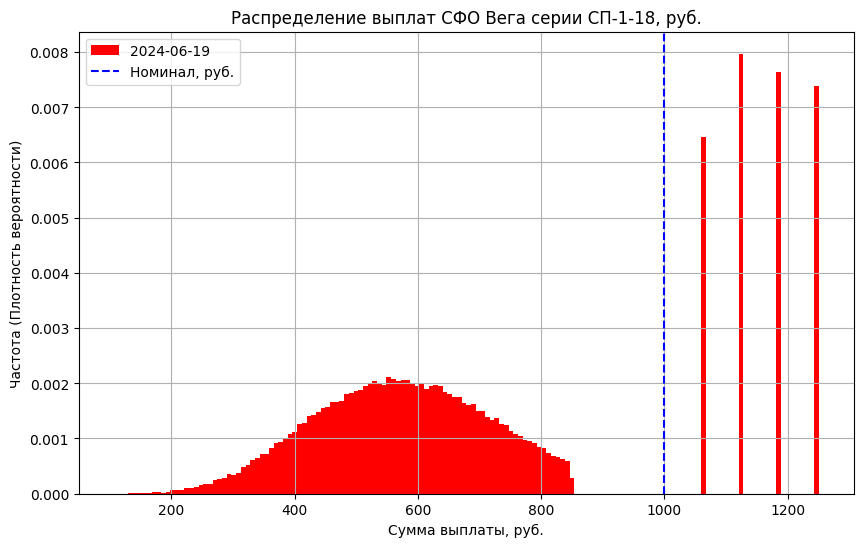

In [ ]:
# Визуализация
plt.figure(figsize=(10, 6))
plt.hist(payoffs, bins = 150, density = True, color = 'r',alpha = 1, label = val_date )
plt.axvline(x=product['principal'], color='b', linestyle='--', label='Номинал, руб.')

plt.title("Распределение выплат СФО Вега серии СП-1-18, руб.")
plt.xlabel("Сумма выплаты, руб.")
plt.ylabel("Частота (Плотность вероятности)")
plt.legend()
plt.grid()
plt.show()

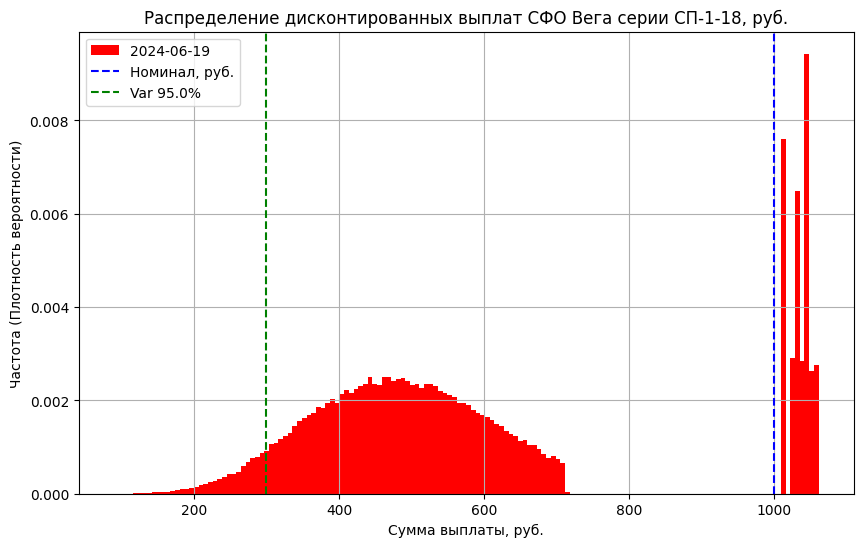

In [ ]:
# Визуализация
confidence_level = 0.95
var = np.percentile(discounted_payoffs, 100 * (1 - confidence_level))

plt.figure(figsize=(10, 6))
plt.hist(discounted_payoffs, bins = 150, density = True, color = 'r',alpha = 1, label = val_date )
plt.axvline(x=product['principal'], color='b', linestyle='--', label='Номинал, руб.')
plt.axvline(x=var, color='g', linestyle='--', label=f'Var {confidence_level*100}%')

plt.title("Распределение дисконтированных выплат СФО Вега серии СП-1-18, руб.")
plt.xlabel("Сумма выплаты, руб.")
plt.ylabel("Частота (Плотность вероятности)")
plt.legend()
plt.grid()
plt.show()